## Configuration-Resolved Dissipation and Coherence

We use one Lindblad jump for each configuration $z$ and spin $i$:

$$
L_{i,z}=\sqrt{W_i(z)}\,|z^{(i)}\rangle\langle z|,
\qquad
W_i(z)=\frac{\gamma_i}{1+e^{-\beta_{\mathrm{eff}}\Delta_i C(z)}}.
$$

Here, $z^{(i)}$ is obtained by flipping spin $i$, and
$\Delta_i C(z)=C(z^{(i)})-C(z)$. These rates favor cut-improving
transitions without requiring knowledge of the optimal solution.
For three spins, there are $3\times2^3=24$ separate jumps.

These jumps redistribute populations and damp computational-basis
coherences:

$$
\left.\dot{\rho}_{zz'}\right|_{\mathrm{diss}}
=-\frac{r(z)+r(z')}{2}\rho_{zz'},
\qquad
r(z)=\sum_iW_i(z),\quad z\ne z'.
$$

We quantify coherence using the normalized off-diagonal sum:

$$
\widetilde C_{l_1}(t)
=\frac{1}{d-1}\sum_{z\ne z'}|\rho_{zz'}(t)|,
\qquad d=8.
$$

- Initially, $|+\rangle^{\otimes3}$ gives $\widetilde C_{l_1}=1$.
- Successful symmetric closed annealing approaches
  $(|001\rangle+|110\rangle)/\sqrt2$, giving
  $\widetilde C_{l_1}=1/7$ while purity remains one.
- With dissipation, coherence evolves through competition between
  Hamiltonian dynamics and dissipative damping.

A decrease in this basis-dependent coherence does not by itself
imply loss of purity or poorer optimization.

Working directory: /Users/saikatmistry/Desktop/Post MS/Open_System_Annealing/03_engineered_dissipation
Figure directory:  /Users/saikatmistry/Desktop/Post MS/Open_System_Annealing/03_engineered_dissipation/figures

Problem
Number of spins: 3
Hilbert-space dimension: 8
Optimal bitstrings: 001, 110
Maximum cut: 5
Minimum problem energy: -5 E0

Dissipator
Number of jump operators: 24
gamma = 0.1 E0/hbar
beta_eff = 5 /E0
Local cost-change and jump-normalization checks passed.
Population-flow and coherence-damping checks passed.

Final observables at T = 100
Model                          P_opt        <C>    E_res/E0   Coherence     Purity
Closed system               0.999899   4.999886    0.000114    0.150581   1.000000
Engineered dissipation      0.975481   4.974972    0.025028    0.064685   0.559866

Numerical diagnostics over the entire ramp
Closed system:
  Maximum trace error:       8.882e-16
  Maximum Hermiticity error: 0.000e+00
  Minimum eigenvalue:        -7.296e-13
Engineered dis

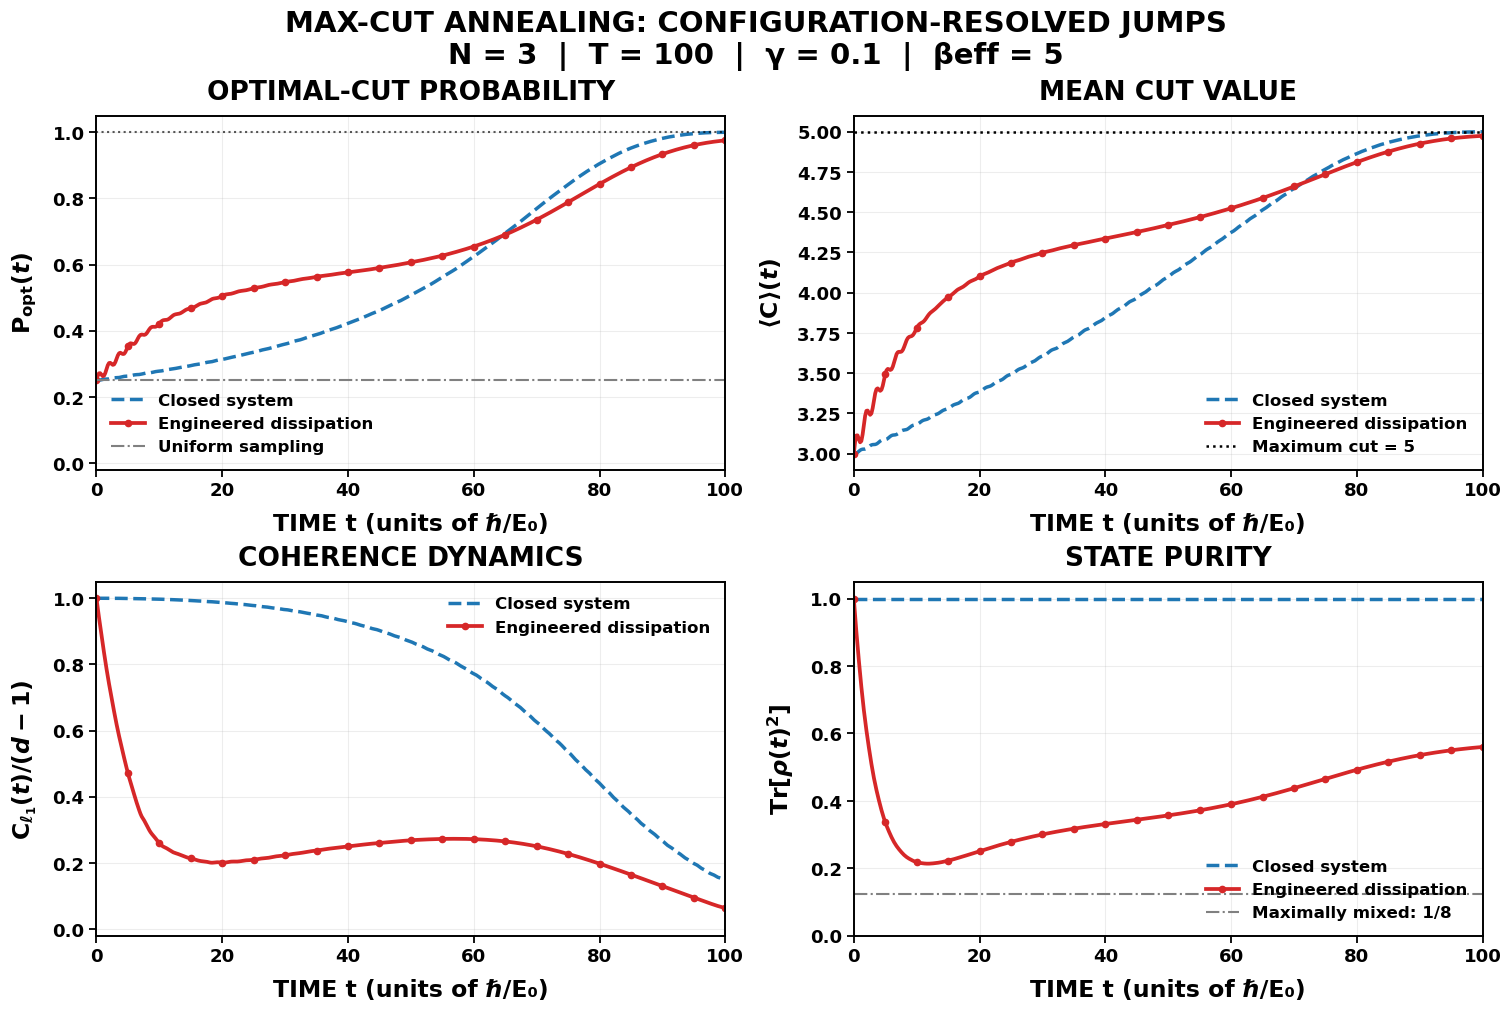


Saved figures:
  PDF: /Users/saikatmistry/Desktop/Post MS/Open_System_Annealing/03_engineered_dissipation/figures/three_spin_configuration_resolved_T100_gamma0.1_beta5.pdf
  PNG: /Users/saikatmistry/Desktop/Post MS/Open_System_Annealing/03_engineered_dissipation/figures/three_spin_configuration_resolved_T100_gamma0.1_beta5.png


In [8]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.special import expit
from pathlib import Path

# ============================================================
# 1. Parameters
# ============================================================
N = 3
dim = 2**N

# Spin 0 corresponds to the leftmost bit.
edges = [
    (0, 1, 1.0),
    (1, 2, 2.0),
    (0, 2, 3.0),
]

J = 1.0
T = 100.0

# Constant engineered-dissipation parameters.
# gamma: units of E0/hbar
# beta_eff: units of 1/E0
gamma = 0.1
beta_eff = 5.0
gamma_sites = np.full(N, gamma)

s_grid = np.linspace(0.0, 1.0, 501)

rtol = 1e-10
atol = 1e-12
diagnostic_tolerance = 1e-8

if T <= 0:
    raise ValueError("T must be positive.")

if beta_eff < 0 or np.any(gamma_sites < 0):
    raise ValueError("Rates and beta_eff must be nonnegative.")

basis_indices = np.arange(dim)
basis_labels = np.array([
    format(z, f"0{N}b") for z in basis_indices
])

# Output directory relative to the notebook's working directory.
import os

project_dir = (
    Path.home()
    / "Desktop"
    / "Post MS"
    / "Open_System_Annealing"
    / "03_engineered_dissipation"
)

if not project_dir.is_dir():
    raise FileNotFoundError(
        f"Project folder not found: {project_dir}\n"
        "In VS Code, right-click the project folder and "
        "select Copy Path to check its location."
    )

# Reset the kernel's working directory to the existing folder.
os.chdir(project_dir)

figure_dir = project_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

print(f"Working directory: {Path.cwd()}")
print(f"Figure directory:  {figure_dir}")

# ============================================================
# 2. Spin operators and Hamiltonians
# ============================================================
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
I_full = np.eye(dim, dtype=complex)


def local_operator(operator, site):
    """Embed a single-spin operator in the N-spin Hilbert space."""
    result = np.array([[1.0]], dtype=complex)

    for j in range(N):
        result = np.kron(
            result,
            operator if j == site else I2,
        )

    return result


X_ops = [local_operator(X, i) for i in range(N)]
Z_ops = [local_operator(Z, i) for i in range(N)]

H_driver = -J * sum(X_ops)
C_op = np.zeros((dim, dim), dtype=complex)

for i, j, weight in edges:
    C_op += 0.5 * weight * (
        I_full - Z_ops[i] @ Z_ops[j]
    )

H_problem = -C_op

cut_values = np.diag(C_op).real
problem_energies = -cut_values

C_max = cut_values.max()
E_min = problem_energies.min()
optimal_mask = np.isclose(cut_values, C_max)

# Used only for diagnostics and performance assessment.
# The jump construction below does not use optimal_mask or E_min.
uniform_success = optimal_mask.sum() / dim


def hamiltonian(s):
    """Linear annealing Hamiltonian, s=t/T."""
    return (1.0 - s) * H_driver + s * H_problem


# ============================================================
# 3. Initial state
# ============================================================
psi_initial = np.ones(dim, dtype=complex) / np.sqrt(dim)
rho_initial = np.outer(psi_initial, psi_initial.conj())

print("\nProblem")
print(f"Number of spins: {N}")
print(f"Hilbert-space dimension: {dim}")
print(f"Optimal bitstrings: {', '.join(basis_labels[optimal_mask])}")
print(f"Maximum cut: {C_max:g}")
print(f"Minimum problem energy: {E_min:g} E0")

# ============================================================
# 4. Configuration-resolved Lindblad operators
#
# L_(i,z) = sqrt(W_i(z)) |z^(i)><z|
#
# W_i(z) = gamma_i / [1 + exp(-beta_eff * Delta_i C(z))]
#
# Rates depend on the fixed problem cost, not on the spectrum
# of the instantaneous annealing Hamiltonian.
# ============================================================

# Eigenvalues of each Z_i in the computational basis.
# Shape: (N, dim)
spin_values = np.array([
    np.diag(Z_i).real for Z_i in Z_ops
])

flip_indices = np.empty((N, dim), dtype=int)
delta_cut = np.zeros((N, dim), dtype=float)
rates = np.zeros((N, dim), dtype=float)

jump_operators = []

for i in range(N):
    # Correct bit position when spin 0 is the leftmost bit.
    bit_mask = 1 << (N - 1 - i)
    flip_indices[i] = basis_indices ^ bit_mask

    # Local field from edges incident on spin i.
    local_field = np.zeros(dim, dtype=float)

    for a, b, weight in edges:
        if a == i:
            local_field += weight * spin_values[b]
        elif b == i:
            local_field += weight * spin_values[a]

    delta_cut[i] = spin_values[i] * local_field

    # Validate the local formula using direct cost differences.
    direct_difference = (
        cut_values[flip_indices[i]] - cut_values
    )

    if not np.allclose(delta_cut[i], direct_difference):
        raise RuntimeError("Local cost-change verification failed.")

    # expit(x) = 1 / (1 + exp(-x)), evaluated stably.
    rates[i] = gamma_sites[i] * expit(
        beta_eff * delta_cut[i]
    )

    for z in basis_indices:
        z_flipped = flip_indices[i, z]

        L = np.zeros((dim, dim), dtype=complex)
        L[z_flipped, z] = np.sqrt(rates[i, z])

        jump_operators.append(L)

jump_operators = np.stack(jump_operators)
jump_daggers = jump_operators.conj().transpose(0, 2, 1)

# K = sum_(i,z) L_(i,z)^dagger L_(i,z)
K = np.sum(jump_daggers @ jump_operators, axis=0)

# Total outgoing rate from each configuration.
escape_rates = rates.sum(axis=0)

if not np.allclose(K, np.diag(escape_rates)):
    raise RuntimeError("Jump normalization verification failed.")

print("\nDissipator")
print(f"Number of jump operators: {len(jump_operators)}")
print(f"gamma = {gamma:g} E0/hbar")
print(f"beta_eff = {beta_eff:g} /E0")
print("Local cost-change and jump-normalization checks passed.")


def dissipator(rho):
    """Sum of separate configuration-resolved dissipators."""
    gain = np.sum(
        jump_operators @ rho @ jump_daggers,
        axis=0,
    )

    loss = 0.5 * (K @ rho + rho @ K)

    return gain - loss


# ============================================================
# 5. Structural checks of the dissipator
# ============================================================
off_diagonal_mask = ~np.eye(dim, dtype=bool)

# A reproducible mixed state containing coherences.
rng = np.random.default_rng(1234)
A = (
    rng.normal(size=(dim, dim))
    + 1j * rng.normal(size=(dim, dim))
)

rho_test = A @ A.conj().T
rho_test /= np.trace(rho_test)

D_test = dissipator(rho_test)
p_test = np.diag(rho_test).real

# Classical gain-loss equation.
classical_dp = np.zeros(dim)

for i in range(N):
    flipped = flip_indices[i]

    classical_dp += (
        rates[i, flipped] * p_test[flipped]
        - rates[i] * p_test
    )

# Exact off-diagonal damping for configuration-resolved jumps.
expected_off_diagonal = -0.5 * (
    escape_rates[:, None] + escape_rates[None, :]
) * rho_test

if not np.allclose(np.diag(D_test), classical_dp):
    raise RuntimeError("Classical population-flow check failed.")

if not np.allclose(
    D_test[off_diagonal_mask],
    expected_off_diagonal[off_diagonal_mask],
):
    raise RuntimeError("Off-diagonal damping check failed.")

print("Population-flow and coherence-damping checks passed.")

# ============================================================
# 6. Density-matrix evolution
# ============================================================
def run_evolution(use_dissipation):
    """Integrate rho in s=t/T, with dt/ds=T."""

    def density_rhs(s, rho_flat):
        rho = rho_flat.reshape(dim, dim)
        H = hamiltonian(s)

        drho_dt = -1j * (H @ rho - rho @ H)

        if use_dissipation:
            drho_dt += dissipator(rho)

        # Multiply BOTH Hamiltonian and dissipative terms by T.
        return (T * drho_dt).ravel()

    solution = solve_ivp(
        density_rhs,
        (0.0, 1.0),
        rho_initial.ravel(),
        t_eval=s_grid,
        method="DOP853",
        rtol=rtol,
        atol=atol,
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    rho_history = solution.y.T.reshape(-1, dim, dim)

    populations = np.diagonal(
        rho_history,
        axis1=1,
        axis2=2,
    ).real

    P_opt = populations[:, optimal_mask].sum(axis=1)
    mean_cut = populations @ cut_values
    mean_problem_energy = populations @ problem_energies

    # Normalized l1 coherence in the computational basis.
    coherence_l1 = np.sum(
        np.abs(rho_history[:, off_diagonal_mask]),
        axis=1,
    ) / (dim - 1)

    purity = np.einsum(
        "tij,tji->t",
        rho_history,
        rho_history,
    ).real

    traces = np.trace(
        rho_history,
        axis1=1,
        axis2=2,
    )

    rho_dagger = rho_history.conj().transpose(0, 2, 1)

    hermiticity_errors = np.linalg.norm(
        rho_history - rho_dagger,
        axis=(1, 2),
    )

    # Symmetrize ONLY for the eigenvalue diagnostic.
    rho_hermitian = 0.5 * (rho_history + rho_dagger)
    min_eigenvalues = np.linalg.eigvalsh(
        rho_hermitian
    )[:, 0]

    # No clipping, renormalization, or state repair.
    return {
        "s": solution.t,
        "t": T * solution.t,
        "rho": rho_history,
        "populations": populations,
        "P_opt": P_opt,
        "mean_cut": mean_cut,
        "mean_problem_energy": mean_problem_energy,
        "residual_energy": mean_problem_energy - E_min,
        "coherence_l1": coherence_l1,
        "purity": purity,
        "trace_error": np.max(np.abs(traces - 1.0)),
        "hermiticity_error": np.max(hermiticity_errors),
        "min_eigenvalue": np.min(min_eigenvalues),
    }


results = {
    "Closed system": run_evolution(use_dissipation=False),
    "Engineered dissipation": run_evolution(use_dissipation=True),
}

# ============================================================
# 7. Final observables and numerical diagnostics
# ============================================================
print(f"\nFinal observables at T = {T:g}")

print(
    f"{'Model':<25}"
    f"{'P_opt':>11}"
    f"{'<C>':>11}"
    f"{'E_res/E0':>12}"
    f"{'Coherence':>12}"
    f"{'Purity':>11}"
)

for name, result in results.items():
    print(
        f"{name:<25}"
        f"{result['P_opt'][-1]:11.6f}"
        f"{result['mean_cut'][-1]:11.6f}"
        f"{result['residual_energy'][-1]:12.6f}"
        f"{result['coherence_l1'][-1]:12.6f}"
        f"{result['purity'][-1]:11.6f}"
    )

print("\nNumerical diagnostics over the entire ramp")

for name, result in results.items():
    print(
        f"{name}:\n"
        f"  Maximum trace error:       "
        f"{result['trace_error']:.3e}\n"
        f"  Maximum Hermiticity error: "
        f"{result['hermiticity_error']:.3e}\n"
        f"  Minimum eigenvalue:        "
        f"{result['min_eigenvalue']:.3e}"
    )

    if (
        result["trace_error"] > diagnostic_tolerance
        or result["hermiticity_error"] > diagnostic_tolerance
        or result["min_eigenvalue"] < -diagnostic_tolerance
    ):
        print("  WARNING: numerical diagnostics exceed tolerance.")

# Purity conservation is expected only for the closed run.
closed_purity_error = np.max(
    np.abs(results["Closed system"]["purity"] - 1.0)
)

print(
    "\nClosed-system purity-conservation error: "
    f"{closed_purity_error:.3e}"
)

# ============================================================
# 8. Plot styling
# ============================================================
plot_settings = {
    "font.family": "DejaVu Sans",
    "font.size": 14,
    "font.weight": "bold",
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "axes.titlesize": 19,
    "axes.labelsize": 17,
    "axes.linewidth": 1.4,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
    "mathtext.fontset": "dejavusans",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}

model_styles = {
    "Closed system": {
        "color": "tab:blue",
        "linestyle": "--",
        "linewidth": 2.5,
    },
    "Engineered dissipation": {
        "color": "tab:red",
        "linestyle": "-",
        "linewidth": 2.7,
        "marker": "o",
        "markersize": 4.5,
        "markevery": 25,
    },
}

# ============================================================
# 9. Four-panel comparison versus physical time
# ============================================================
with plt.rc_context(plot_settings):
    fig, axes = plt.subplots(
        2, 2,
        figsize=(15, 10),
        constrained_layout=True,
    )

    fig.suptitle(
        "MAX-CUT ANNEALING: CONFIGURATION-RESOLVED JUMPS\n"
        f"N = {N}  |  T = {T:g}  |  "
        f"γ = {gamma:g}  |  βeff = {beta_eff:g}",
        fontsize=21,
        fontweight="bold",
    )

    panels = [
        (
            axes[0, 0],
            "P_opt",
            "OPTIMAL-CUT PROBABILITY",
            r"$\mathbf{P}_{\mathbf{opt}}(t)$",
        ),
        (
            axes[0, 1],
            "mean_cut",
            "MEAN CUT VALUE",
            r"$\langle\mathbf{C}\rangle(t)$",
        ),
        (
            axes[1, 0],
            "coherence_l1",
            "COHERENCE DYNAMICS",
            r"$\mathbf{C}_{\ell_1}(t)/(d-1)$",
        ),
        (
            axes[1, 1],
            "purity",
            "STATE PURITY",
            r"$\mathrm{Tr}[\boldsymbol{\rho}(t)^2]$",
        ),
    ]

    for ax, observable, title, ylabel in panels:
        for name, result in results.items():
            ax.plot(
                result["t"],
                result[observable],
                label=name,
                **model_styles[name],
            )

        ax.set_title(title, pad=12)
        ax.set_xlabel("TIME t (units of ℏ/E₀)", labelpad=9)
        ax.set_ylabel(ylabel, labelpad=10)
        ax.set_xlim(0, T)

        ax.grid(alpha=0.22)
        ax.set_axisbelow(True)
        ax.tick_params(
            axis="both",
            width=1.3,
            length=5,
        )

        for tick in ax.get_xticklabels() + ax.get_yticklabels():
            tick.set_fontweight("bold")

    # Optimal-cut probability.
    axes[0, 0].axhline(
        1.0,
        color="black",
        linestyle=":",
        linewidth=1.5,
        alpha=0.65,
    )
    axes[0, 0].axhline(
        uniform_success,
        color="gray",
        linestyle="-.",
        linewidth=1.5,
        label="Uniform sampling",
    )
    axes[0, 0].set_ylim(-0.02, 1.05)

    # Mean cut.
    axes[0, 1].axhline(
        C_max,
        color="black",
        linestyle=":",
        linewidth=1.8,
        label=f"Maximum cut = {C_max:g}",
    )

    # Normalized coherence.
    axes[1, 0].set_ylim(-0.02, 1.05)

    # Purity.
    axes[1, 1].axhline(
        1.0 / dim,
        color="gray",
        linestyle="-.",
        linewidth=1.5,
        label=f"Maximally mixed: 1/{dim}",
    )
    axes[1, 1].set_ylim(0, 1.05)

    for ax in axes.flat:
        ax.legend(
            loc="best",
            frameon=False,
            prop={"weight": "bold", "size": 12},
        )

    # Save before displaying.
    filename = (
        f"three_spin_configuration_resolved"
        f"_T{T:g}_gamma{gamma:g}_beta{beta_eff:g}"
    )

    pdf_path = figure_dir / f"{filename}.pdf"
    png_path = figure_dir / f"{filename}.png"

    fig.savefig(pdf_path, bbox_inches="tight")
    fig.savefig(png_path, dpi=300, bbox_inches="tight")

    plt.show()

print("\nSaved figures:")
print(f"  PDF: {pdf_path.resolve()}")
print(f"  PNG: {png_path.resolve()}")

## Conditional Lindblad Jumps

We use one jump per spin:

$$
L_i=X_i\sqrt{F_i},
\qquad
F_i=\gamma_i\left[I+e^{-\beta_{\mathrm{eff}}\Delta_i\widehat C}\right]^{-1},
\qquad
\Delta_i\widehat C=Z_i\sum_{j\in\mathcal N(i)}w_{ij}Z_j.
$$

The rate is evaluated before the flip:
$L_i|z\rangle=\sqrt{W_i(z)}|z^{(i)}\rangle$.

This gives **3 jumps instead of 24**. It produces the same dissipative
population equation as configuration-resolved jumps, but includes
coherence-transfer terms. Consequently, the full annealing dynamics
can differ when the transverse-field driver is present.

The dissipator alone does not generate computational-basis coherence
from a diagonal state.

Working directory: /Users/saikatmistry/Desktop/Post MS/Open_System_Annealing/03_engineered_dissipation
Figure directory: /Users/saikatmistry/Desktop/Post MS/Open_System_Annealing/03_engineered_dissipation/figures

Problem
Optimal bitstrings: 001, 110
Maximum cut: 5
Minimum problem energy: -5 E0

Dissipator
Construction: one conditional jump per spin
Number of jump operators: 3
gamma = 0.1 E0/hbar
beta_eff = 5 /E0
Jump-action, population-flow, and coherence-transfer checks passed.

Final observables at T = 100
Model                        P_opt        <C>    E_res/E0   Coherence     Purity
Closed system             0.999899   4.999886    0.000114    0.150581   1.000000
Conditional jumps         0.972655   4.972339    0.027661    0.150051   0.946981

Numerical diagnostics over the entire ramp
Closed system:
  Maximum trace error:       8.882e-16
  Maximum Hermiticity error: 0.000e+00
  Minimum eigenvalue:        -7.296e-13
Conditional jumps:
  Maximum trace error:       3.810e-15
  Maxim

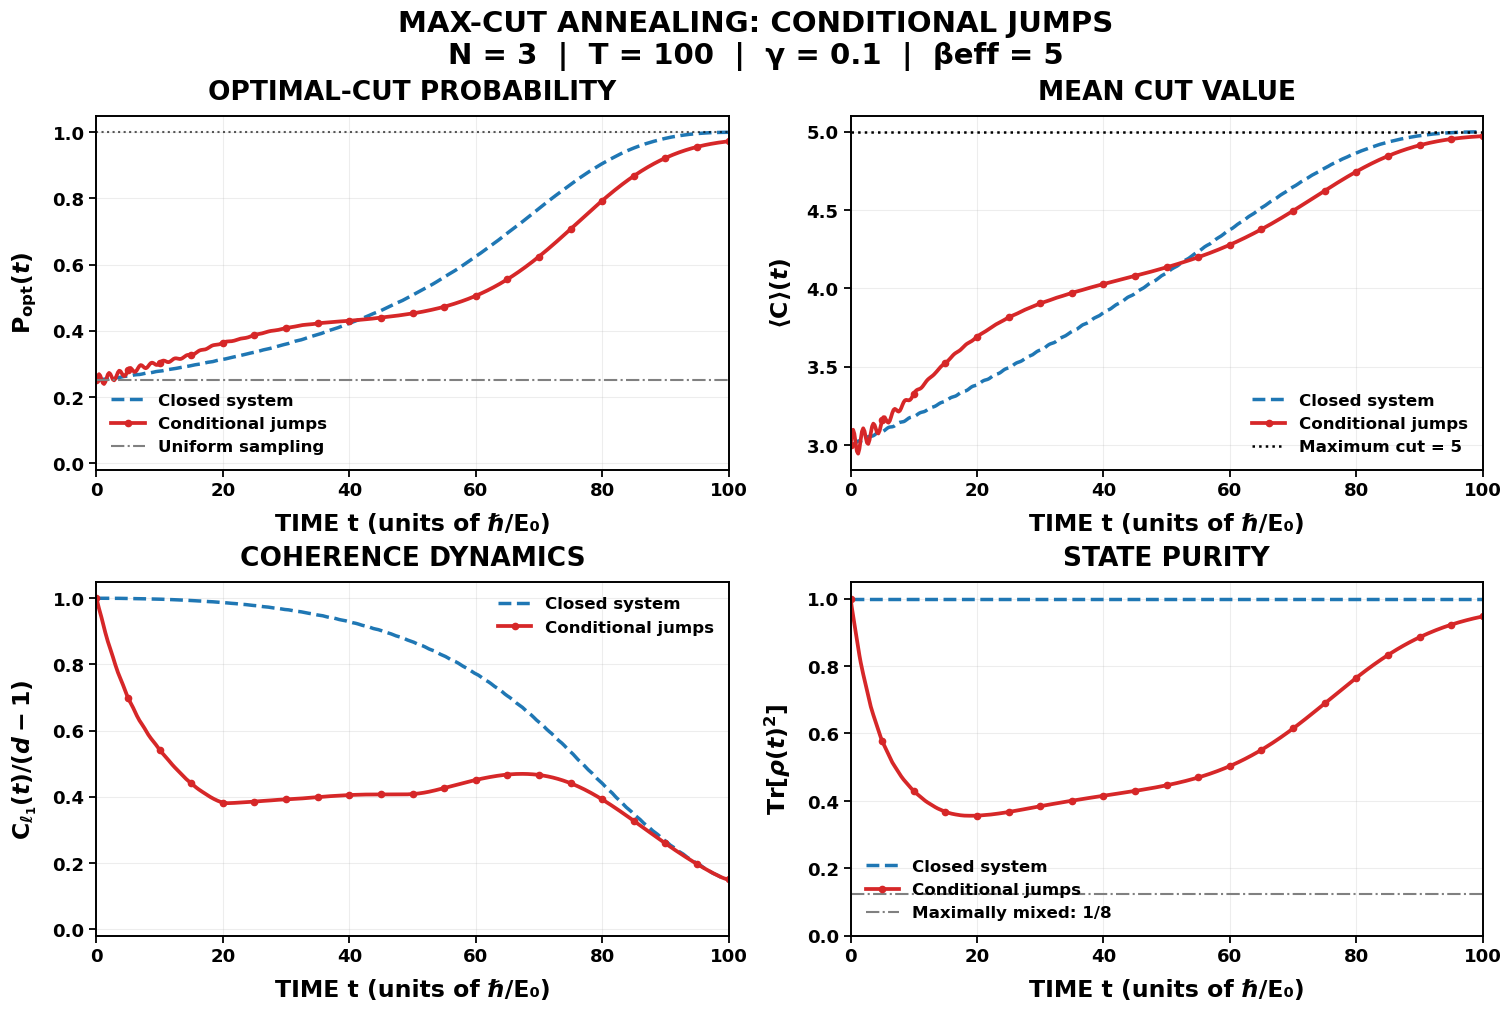


Saved figures:
  PDF: /Users/saikatmistry/Desktop/Post MS/Open_System_Annealing/03_engineered_dissipation/figures/three_spin_conditional_jumps_T100_gamma0.1_beta5.pdf
  PNG: /Users/saikatmistry/Desktop/Post MS/Open_System_Annealing/03_engineered_dissipation/figures/three_spin_conditional_jumps_T100_gamma0.1_beta5.png


In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.special import expit
from pathlib import Path

# ============================================================
# 1. Parameters
# ============================================================
N = 3
dim = 2**N

# Spin 0 is the leftmost bit.
edges = [
    (0, 1, 1.0),
    (1, 2, 2.0),
    (0, 2, 3.0),
]

J = 1.0
T = 100.0

gamma = 0.1
beta_eff = 5.0
gamma_sites = np.full(N, gamma)

s_grid = np.linspace(0.0, 1.0, 501)
rtol = 1e-10
atol = 1e-12
diagnostic_tolerance = 1e-8

if T <= 0:
    raise ValueError("T must be positive.")

if beta_eff < 0 or np.any(gamma_sites < 0):
    raise ValueError("beta_eff and rates must be nonnegative.")

basis_indices = np.arange(dim)
basis_labels = np.array([
    format(z, f"0{N}b") for z in basis_indices
])

# ============================================================
# 2. Figure directory
# ============================================================
project_dir = (
    Path.home()
    / "Desktop"
    / "Post MS"
    / "Open_System_Annealing"
    / "03_engineered_dissipation"
)

if not project_dir.is_dir():
    raise FileNotFoundError(
        f"Project folder not found: {project_dir}\n"
        "Update project_dir to your actual folder location."
    )

os.chdir(project_dir)

figure_dir = project_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

print(f"Working directory: {Path.cwd()}")
print(f"Figure directory: {figure_dir}")

# ============================================================
# 3. Spin operators and Hamiltonians
# ============================================================
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
I_full = np.eye(dim, dtype=complex)


def local_operator(operator, site):
    result = np.array([[1.0]], dtype=complex)

    for j in range(N):
        result = np.kron(
            result,
            operator if j == site else I2,
        )

    return result


X_ops = [local_operator(X, i) for i in range(N)]
Z_ops = [local_operator(Z, i) for i in range(N)]

H_driver = -J * sum(X_ops)
C_op = np.zeros((dim, dim), dtype=complex)

for i, j, weight in edges:
    C_op += 0.5 * weight * (
        I_full - Z_ops[i] @ Z_ops[j]
    )

H_problem = -C_op

cut_values = np.diag(C_op).real
problem_energies = -cut_values

# Used only to evaluate performance, not to construct jumps.
C_max = cut_values.max()
E_min = problem_energies.min()
optimal_mask = np.isclose(cut_values, C_max)
uniform_success = optimal_mask.sum() / dim


def hamiltonian(s):
    return (1.0 - s) * H_driver + s * H_problem


# ============================================================
# 4. Initial state
# ============================================================
psi_initial = np.ones(dim, dtype=complex) / np.sqrt(dim)
rho_initial = np.outer(psi_initial, psi_initial.conj())

print("\nProblem")
print(f"Optimal bitstrings: {', '.join(basis_labels[optimal_mask])}")
print(f"Maximum cut: {C_max:g}")
print(f"Minimum problem energy: {E_min:g} E0")

# ============================================================
# 5. Conditional Lindblad construction
#
# Delta_i C_hat = Z_i sum_j w_ij Z_j
# F_i = gamma_i [I + exp(-beta_eff Delta_i C_hat)]^(-1)
# L_i = X_i sqrt(F_i)
#
# One jump per spin: N=3 jumps.
# ============================================================
flip_indices = np.empty((N, dim), dtype=int)
delta_cut = np.zeros((N, dim))
rates = np.zeros((N, dim))

cost_change_operators = []
rate_operators = []
jump_operators = []

for i in range(N):
    flip_indices[i] = (
        basis_indices ^ (1 << (N - 1 - i))
    )

    neighbor_field = np.zeros((dim, dim), dtype=complex)

    for a, b, weight in edges:
        if a == i:
            neighbor_field += weight * Z_ops[b]
        elif b == i:
            neighbor_field += weight * Z_ops[a]

    delta_C_operator = Z_ops[i] @ neighbor_field
    delta_cut[i] = np.diag(delta_C_operator).real

    # Check against direct cut differences.
    direct_difference = (
        cut_values[flip_indices[i]] - cut_values
    )

    if not np.allclose(delta_cut[i], direct_difference):
        raise RuntimeError("Local cost-change check failed.")

    # F_i is diagonal, so evaluate its function entrywise.
    # expit(x) = 1 / (1 + exp(-x)).
    rates[i] = gamma_sites[i] * expit(
        beta_eff * delta_cut[i]
    )

    F_i = np.diag(rates[i]).astype(complex)
    sqrt_F_i = np.diag(np.sqrt(rates[i])).astype(complex)

    # IMPORTANT: sqrt(F_i) acts first, then X_i flips the spin.
    L_i = X_ops[i] @ sqrt_F_i

    if not np.allclose(L_i.conj().T @ L_i, F_i):
        raise RuntimeError("L_i^dagger L_i = F_i check failed.")

    # Verify every computational-basis transition.
    expected_L = np.zeros((dim, dim), dtype=complex)
    expected_L[flip_indices[i], basis_indices] = np.sqrt(rates[i])

    if not np.allclose(L_i, expected_L):
        raise RuntimeError("Conditional jump-action check failed.")

    cost_change_operators.append(delta_C_operator)
    rate_operators.append(F_i)
    jump_operators.append(L_i)

jump_operators = np.stack(jump_operators)
jump_daggers = jump_operators.conj().transpose(0, 2, 1)

K = np.sum(jump_daggers @ jump_operators, axis=0)
escape_rates = rates.sum(axis=0)

print("\nDissipator")
print(f"Construction: one conditional jump per spin")
print(f"Number of jump operators: {len(jump_operators)}")
print(f"gamma = {gamma:g} E0/hbar")
print(f"beta_eff = {beta_eff:g} /E0")


def dissipator(rho):
    """Sum_i D[L_i](rho), with each L_i = X_i sqrt(F_i)."""
    gain = np.sum(
        jump_operators @ rho @ jump_daggers,
        axis=0,
    )
    loss = 0.5 * (K @ rho + rho @ K)
    return gain - loss


# ============================================================
# 6. Check populations AND coherence-transfer terms
#
# D(rho)_(a,b) =
# sum_i sqrt[W_i(a^i) W_i(b^i)] rho_(a^i,b^i)
# - 1/2 [r(a)+r(b)] rho_(a,b)
#
# Unlike configuration-resolved jumps, the gain term also
# transfers off-diagonal elements.
# ============================================================
off_diagonal_mask = ~np.eye(dim, dtype=bool)

rng = np.random.default_rng(1234)
A = (
    rng.normal(size=(dim, dim))
    + 1j * rng.normal(size=(dim, dim))
)

rho_test = A @ A.conj().T
rho_test /= np.trace(rho_test)

D_test = dissipator(rho_test)
D_expected = np.zeros_like(rho_test)

for i in range(N):
    flipped = flip_indices[i]
    incoming_amplitudes = np.sqrt(rates[i, flipped])

    D_expected += (
        incoming_amplitudes[:, None]
        * incoming_amplitudes[None, :]
        * rho_test[np.ix_(flipped, flipped)]
    )

D_expected -= 0.5 * (
    escape_rates[:, None] + escape_rates[None, :]
) * rho_test

if not np.allclose(D_test, D_expected):
    raise RuntimeError("Conditional coherence-transfer check failed.")

# Diagonal elements must still obey the classical gain-loss law.
p_test = np.diag(rho_test).real
classical_dp = np.zeros(dim)

for i in range(N):
    flipped = flip_indices[i]
    classical_dp += (
        rates[i, flipped] * p_test[flipped]
        - rates[i] * p_test
    )

if not np.allclose(np.diag(D_test), classical_dp):
    raise RuntimeError("Classical population-flow check failed.")

print("Jump-action, population-flow, and coherence-transfer checks passed.")

# ============================================================
# 7. Density-matrix evolution
# ============================================================
def run_evolution(use_dissipation):
    def density_rhs(s, rho_flat):
        rho = rho_flat.reshape(dim, dim)
        H = hamiltonian(s)

        drho_dt = -1j * (H @ rho - rho @ H)

        if use_dissipation:
            drho_dt += dissipator(rho)

        # Integrating in s=t/T requires multiplying everything by T.
        return (T * drho_dt).ravel()

    solution = solve_ivp(
        density_rhs,
        (0.0, 1.0),
        rho_initial.ravel(),
        t_eval=s_grid,
        method="DOP853",
        rtol=rtol,
        atol=atol,
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    rho_history = solution.y.T.reshape(-1, dim, dim)

    populations = np.diagonal(
        rho_history, axis1=1, axis2=2
    ).real

    coherence_l1 = np.sum(
        np.abs(rho_history[:, off_diagonal_mask]),
        axis=1,
    ) / (dim - 1)

    purity = np.einsum(
        "tij,tji->t", rho_history, rho_history
    ).real

    traces = np.trace(rho_history, axis1=1, axis2=2)
    rho_dagger = rho_history.conj().transpose(0, 2, 1)

    hermiticity_errors = np.linalg.norm(
        rho_history - rho_dagger, axis=(1, 2)
    )

    # Symmetrization ONLY for eigenvalue diagnostics.
    rho_hermitian = 0.5 * (rho_history + rho_dagger)
    min_eigenvalue = np.linalg.eigvalsh(rho_hermitian).min()

    mean_energy = populations @ problem_energies

    # No state renormalization or eigenvalue clipping.
    return {
        "s": solution.t,
        "t": T * solution.t,
        "rho": rho_history,
        "populations": populations,
        "P_opt": populations[:, optimal_mask].sum(axis=1),
        "mean_cut": populations @ cut_values,
        "mean_problem_energy": mean_energy,
        "residual_energy": mean_energy - E_min,
        "coherence_l1": coherence_l1,
        "purity": purity,
        "trace_error": np.max(np.abs(traces - 1.0)),
        "hermiticity_error": np.max(hermiticity_errors),
        "min_eigenvalue": min_eigenvalue,
    }


# Separate name to distinguish this run from the previous cell.
conditional_results = {
    "Closed system": run_evolution(False),
    "Conditional jumps": run_evolution(True),
}

# ============================================================
# 8. Final results and diagnostics
# ============================================================
print(f"\nFinal observables at T = {T:g}")
print(
    f"{'Model':<23}"
    f"{'P_opt':>11}"
    f"{'<C>':>11}"
    f"{'E_res/E0':>12}"
    f"{'Coherence':>12}"
    f"{'Purity':>11}"
)

for name, result in conditional_results.items():
    print(
        f"{name:<23}"
        f"{result['P_opt'][-1]:11.6f}"
        f"{result['mean_cut'][-1]:11.6f}"
        f"{result['residual_energy'][-1]:12.6f}"
        f"{result['coherence_l1'][-1]:12.6f}"
        f"{result['purity'][-1]:11.6f}"
    )

print("\nNumerical diagnostics over the entire ramp")

for name, result in conditional_results.items():
    print(
        f"{name}:\n"
        f"  Maximum trace error:       {result['trace_error']:.3e}\n"
        f"  Maximum Hermiticity error: {result['hermiticity_error']:.3e}\n"
        f"  Minimum eigenvalue:        {result['min_eigenvalue']:.3e}"
    )

    if (
        result["trace_error"] > diagnostic_tolerance
        or result["hermiticity_error"] > diagnostic_tolerance
        or result["min_eigenvalue"] < -diagnostic_tolerance
    ):
        print("  WARNING: numerical diagnostics exceed tolerance.")

closed_purity_error = np.max(np.abs(
    conditional_results["Closed system"]["purity"] - 1.0
))

print(
    "\nClosed-system purity-conservation error: "
    f"{closed_purity_error:.3e}"
)

# ============================================================
# 9. Bold plot styling
# ============================================================
plot_settings = {
    "font.family": "DejaVu Sans",
    "font.size": 14,
    "font.weight": "bold",
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "axes.titlesize": 19,
    "axes.labelsize": 17,
    "axes.linewidth": 1.4,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "mathtext.fontset": "dejavusans",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}

model_styles = {
    "Closed system": {
        "color": "tab:blue",
        "linestyle": "--",
        "linewidth": 2.5,
    },
    "Conditional jumps": {
        "color": "tab:red",
        "linestyle": "-",
        "linewidth": 2.7,
        "marker": "o",
        "markersize": 4.5,
        "markevery": 25,
    },
}

# ============================================================
# 10. Four-panel comparison
# ============================================================
with plt.rc_context(plot_settings):
    fig, axes = plt.subplots(
        2, 2,
        figsize=(15, 10),
        constrained_layout=True,
    )

    fig.suptitle(
        "MAX-CUT ANNEALING: CONDITIONAL JUMPS\n"
        f"N = {N}  |  T = {T:g}  |  "
        f"γ = {gamma:g}  |  βeff = {beta_eff:g}",
        fontsize=21,
        fontweight="bold",
    )

    panels = [
        (
            axes[0, 0], "P_opt",
            "OPTIMAL-CUT PROBABILITY",
            r"$\mathbf{P}_{\mathbf{opt}}(t)$",
        ),
        (
            axes[0, 1], "mean_cut",
            "MEAN CUT VALUE",
            r"$\langle\mathbf{C}\rangle(t)$",
        ),
        (
            axes[1, 0], "coherence_l1",
            "COHERENCE DYNAMICS",
            r"$\mathbf{C}_{\ell_1}(t)/(d-1)$",
        ),
        (
            axes[1, 1], "purity",
            "STATE PURITY",
            r"$\mathrm{Tr}[\boldsymbol{\rho}(t)^2]$",
        ),
    ]

    for ax, observable, title, ylabel in panels:
        for name, result in conditional_results.items():
            ax.plot(
                result["t"],
                result[observable],
                label=name,
                **model_styles[name],
            )

        ax.set_title(title, pad=12)
        ax.set_xlabel("TIME t (units of ℏ/E₀)", labelpad=9)
        ax.set_ylabel(ylabel, labelpad=10)
        ax.set_xlim(0, T)
        ax.grid(alpha=0.22)
        ax.set_axisbelow(True)
        ax.tick_params(width=1.3, length=5)

        for tick in ax.get_xticklabels() + ax.get_yticklabels():
            tick.set_fontweight("bold")

    axes[0, 0].axhline(
        1.0, color="black", linestyle=":",
        linewidth=1.5, alpha=0.65,
    )
    axes[0, 0].axhline(
        uniform_success, color="gray", linestyle="-.",
        linewidth=1.5, label="Uniform sampling",
    )
    axes[0, 0].set_ylim(-0.02, 1.05)

    axes[0, 1].axhline(
        C_max, color="black", linestyle=":",
        linewidth=1.8, label=f"Maximum cut = {C_max:g}",
    )

    axes[1, 0].set_ylim(-0.02, 1.05)

    axes[1, 1].axhline(
        1.0 / dim, color="gray", linestyle="-.",
        linewidth=1.5, label=f"Maximally mixed: 1/{dim}",
    )
    axes[1, 1].set_ylim(0, 1.05)

    for ax in axes.flat:
        ax.legend(
            loc="best",
            frameon=False,
            prop={"weight": "bold", "size": 12},
        )

    filename = (
        f"three_spin_conditional_jumps"
        f"_T{T:g}_gamma{gamma:g}_beta{beta_eff:g}"
    )

    pdf_path = figure_dir / f"{filename}.pdf"
    png_path = figure_dir / f"{filename}.png"

    fig.savefig(pdf_path, bbox_inches="tight")
    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    plt.show()

print("\nSaved figures:")
print(f"  PDF: {pdf_path}")
print(f"  PNG: {png_path}")